# OKR analysis template

Developed: September, 2023 (Angueyra)

Steps:
1. Load video into [_napari_](https://napari.org/stable/)
1. Generate _mip_ (maximum intensity projection)
1. Create _labels_ layer and manually define _roa_ (region of analysis) using _mip_
1. Use [_cellpose_](https://cellpose.readthedocs.io/en/latest/index.html) to segment video (_roa_ will be used to mask video)
1. Check segmentation and fix mistakes
1. Use [_btrack_](https://btrack.readthedocs.io/en/latest/index.html) to bind objects through time
1. Use [_skimage_](https://scikit-image.org/docs/stable/api/skimage.measure.html#skimage.measure.EllipseModel) to fit ellipses and get angle data


Tools that could be useful:
1. Rerun cellpose on a single frame
1. Copy segmentation from previous frame into current frame
1. Fill missing frames with average from bracketing frames
1. Split and merge labels

Other Important Notes:
1. Ignore the warnings here for now as of 10/22/2025
1. Need to include cell_config.json in data directory
1. Need to include juanNaparifx.py plotparams.py as well as most recent OKR analysis file in analysis folder 

## Import useful libraries

In [1]:
# image analysis
import napari
from magicgui import magicgui
from enum import Enum
from napari.utils import nbscreenshot
from tifffile import imread
from tifffile import imwrite
import skimage
import cellpose_napari
import cellpose
from cellpose import models
# import btrack
# python basics and plotting
import numpy as np
import pandas as pd
import math
from scipy import ndimage
from scipy.stats import kruskal
from scipy.stats import zscore
from scipy.stats import sem
import scipy.spatial
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as font_manager
import svgutils
from svgutils.compose import *
# system interaction
import os
import os.path
import time, sys, warnings, re
from tqdm.notebook import tqdm, trange
import importlib
import ipywidgets
from IPython.display import display
# lab brews
from plotParams import *
# from juanNapariFx import *

def getFileList(dirData,gene='',fileNameMatch='',addDetails=''):
    fileList = sorted([f for f in os.listdir(dirData) if not f.startswith('.')]) # get all the files in the data directory (excluding system files) and sort them alphabatically
    fileList = ([f for f in fileList if gene in f]) # select files that match the gene of interest
    fileList = ([f for f in fileList if any([s in f for s in fileNameMatch])]) # only keep relevant files
    if (addDetails=='path'):
        fileList = (['# filePath = \'' + f for f in fileList]) # add text before each file
        fileList = list(map(lambda st: str.replace(st, '.nd2', '\'; gene = \'' + gene + '\'; '), fileList)) #remove file extension (.nd2) and add text after each file
    elif (addDetails=='list'):
        fileList = (['\'' + f for f in fileList]) # add text before each file
        fileList = list(map(lambda st: str.replace(st, '.nd2', '\','), fileList)) #remove file extension (.nd2) and add text after each file
    else:
        fileList = list(map(lambda st: str.replace(st, '.nd2', ''), fileList)) #remove file extension (.nd2) and add text after each file
    return fileList


pBGMenu = ipywidgets.Dropdown(options=['Light', 'Dark'],value='Dark',disabled=False, layout=ipywidgets.Layout(width='20%', height='40px'))
pBGLabel = ipywidgets.widgets.Label('Select plotting style', layout=ipywidgets.Layout(width='20%', height='30px'))
pBG = ipywidgets.widgets.VBox([pBGLabel,pBGMenu])
pBG

# Define Directories

In [3]:
# define where all the imaging data is stored 
# IMPORTANT need to include Drive:/folder/folder/file/ need forward slash at end 
# dirData = '/Volumes/vsdDrive/vsdlBeh/20230901_7dpf_OKR/'
# dirData = 'D:/zfBehavior/OKR/20230915_OKR/'
# dirData = 'D:/zfBehavior/OKR/20231024_OKR/'
# dirData = 'D:/zfBehavior/OKR/20231201_OKR/'
# dirData = 'D:/zfBehavior/OKR/20240125_OKR/'
# dirData = 'D:/zfBehavior/OKR/20240202_OKR/'
dirData = 'B:/OKR/Data/SOFIA_OKR/20251105_5dpf_color_Tbx2a/'
dirData = 'B:/OKR/Data/SOFIA_OKR/20251119_5dpf_color_Tbx2a/'



# define where all the analysis files should be stored
# IMPORTANT need to include Drive:/folder/folder/file/ need forward slash at end 
# subdirectories for each gene and transgenic lines need to be manually made first
# dirAnalysis = 'D:/zfBehavior/OKR/20230915_OKR/'
# dirAnalysis = 'D:/zfBehavior/OKR/20231024_OKR/'
# dirAnalysis = 'D:/zfBehavior/OKR/20231201_OKR/'
# dirAnalysis = 'D:/zfBehavior/OKR/20240125_OKR/'
# dirAnalysis = 'B:/OKR/Analysis/20252909_AL_SA_OKRAnalysis/'
dirAnalysis = 'B:/OKR/Analysis/20251119_5dpf_color_Tbx2a/'


In [17]:
gene = '' # usually 'wt' or gene of interest (e.g. 'tbx2a', 'lhx1a')
# gene = 'lhx1a' # usually 'wt' or gene of interest (e.g. 'tbx2a', 'lhx1a')
fileNameMatch = '.tif' # characters in filenames that define zoom-in files

# get a list with all the relevant files
print(*getFileList(dirData,gene,fileNameMatch,addDetails='path'), sep = "\n") #display the file list for copy and paste below

# filePath = '11052025hetcolor0.00_001.tif
# filePath = '11052025hetcolor0.00_001_eyeL_track.npy
# filePath = '11052025hetcolor0.00_001_eyeR_track.npy
# filePath = '11052025hetcolor0.00_001_mip.ome.tif
# filePath = '11052025hetcolor0.00_001_roa.ome.tif
# filePath = '11052025hetcolor0.00_001_sb_track.npy
# filePath = '11052025hetcolor0.00_001_seg.ome.tif
# filePath = '11052025hetcolor0.00_002.tif
# filePath = '11052025hetcolor0.10_001.tif
# filePath = '11052025hetcolor0.10_001_eyeL_track.npy
# filePath = '11052025hetcolor0.10_001_eyeR_track.npy
# filePath = '11052025hetcolor0.10_001_sb_track.npy
# filePath = '11052025hetcolor0.10_002.tif
# filePath = '11052025hetcolor0.20_001.tif
# filePath = '11052025hetcolor0.20_001_eyeL_track.npy
# filePath = '11052025hetcolor0.20_001_eyeR_track.npy
# filePath = '11052025hetcolor0.20_001_sb_track.npy
# filePath = '11052025hetcolor0.20_002.tif
# filePath = '11052025hetcolor0.30_001.tif
# filePath = '11052025hetcolor0.30_001_eyeL_track.npy
# filePath =

In [12]:
# list all files in dirData
os.listdir(dirData)

['11052025hetcolor0.00_001.tif',
 '11052025hetcolor0.10_001.tif',
 '11052025hetcolor0.20_001.tif',
 '11052025hetcolor0.30_001.tif',
 '11052025hetcolor0.40_001.tif',
 '11052025hetcolor0.50_001.tif',
 '11052025hetcolor0.60_001.tif',
 '11052025hetcolor0.70_001.tif',
 '11052025hetcolor0.80_001.tif',
 '11052025hetcolor0.90_001.tif',
 '11052025hetcolor0.999_001.tif',
 '11052025hetcolor0.00_002.tif',
 '11052025hetcolor0.10_002.tif',
 '11052025hetcolor0.20_002.tif',
 '11052025hetcolor0.30_002.tif',
 '11052025hetcolor0.40_002.tif',
 '11052025hetcolor0.50_002.tif',
 '11052025hetcolor0.60_002.tif',
 '11052025hetcolor0.70_002.tif',
 '11052025hetcolor0.80_002.tif',
 '11052025hetcolor0.90_002.tif',
 '11052025hetcolor0.999_002.tif',
 '11052025hetcolor0.999_002.avi',
 'Thumbs.db',
 '11052025hetcolor0.00_001_mip.ome.tif',
 '11052025hetcolor0.00_001_roa.ome.tif',
 '11052025hetcolor0.00_001_seg.ome.tif',
 '11052025hetcolor0.00_001_eyeL_track.npy',
 '11052025hetcolor0.00_001_eyeR_track.npy',
 '11052025het

## Open napari and load video

In [8]:
# open napari
applyPlotStyle(pBGMenu.value)
viewer = napari.Viewer()

Plotting style is Dark
Assistant skips harvesting pyclesperanto as it's not installed.


In [25]:
# viewer.close() 
# If things go wrong or you just need to close it in general use this  (close napari viewer)

In [27]:
# Identify your file path(s)
# filePath = 'name of file' Status 

# Below: 20251013_5dpf_BWSensitivity_Tbx2a

#filePath = '10132025hetcontrast0.01_001.tif' #Not analyzed
#filePath = '10132025hetcontrast0.01_002.tif' #Not analyzed
#filePath = '10132025hetcontrast0.01_003.tif' #Not analyzed
#filePath = '10132025hetcontrast0.01_004.tif' #Not analyzed
#filePath = '10132025hetcontrast0.01_005.tif' #Not analyzed
#filePath = '10132025hetcontrast0.02_001.tif' #Not analyzed
#filePath = '10132025hetcontrast0.02_002.tif' #Not analyzed
#filePath = '10132025hetcontrast0.02_003.tif' #Not analyzed
#filePath = '10132025hetcontrast0.02_004.tif' #Not analyzed
#filePath = '10132025hetcontrast0.02_005.tif' #Not analyzed
#filePath = '10132025hetcontrast0.03_001.tif' #Not analyzed
#filePath = '10132025hetcontrast0.03_003.tif' #Not analyzed
#filePath = '10132025hetcontrast0.03_004.tif' #Not analyzed
#filePath = '10132025hetcontrast0.03_005.tif' #Not analyzed
#filePath = '10132025hetcontrast0.04_001.tif' #Not analyzed
#filePath = '10132025hetcontrast0.04_002.tif' #Not analyzed
#filePath = '10132025hetcontrast0.04_003.tif' #Not analyzed
#filePath = '10132025hetcontrast0.04_004.tif' #Not analyzed
#filePath = '10132025hetcontrast0.04_005.tif' #Not analyzed
#filePath = '10132025hetcontrast0.05_001.tif' #Not analyzed
#filePath = '10132025hetcontrast0.05_002.tif' #Not analyzed
#filePath = '10132025hetcontrast0.05_003.tif' #Not analyzed
#filePath = '10132025hetcontrast0.05_004.tif' #Not analyzed
#filePath = '10132025hetcontrast0.05_005.tif' #Not analyzed
#filePath = '10132025naloucontrast0.01_001.tif' #Not analyzed
#filePath = '10132025naloucontrast0.01_002.tif' #Not analyzed
#filePath = '10132025naloucontrast0.01_003.tif' #Not analyzed
#filePath = '10132025naloucontrast0.01_004.tif' #Not analyzed
#filePath = '10132025naloucontrast0.01_005.tif' #Not analyzed
#filePath = '10132025naloucontrast0.02_001.tif' #Not analyzed
#filePath = '10132025naloucontrast0.02_002.tif' #Not analyzed
#filePath = '10132025naloucontrast0.02_003.tif' #Not analyzed
#filePath = '10132025naloucontrast0.02_004.tif' #Not analyzed
#filePath = '10132025naloucontrast0.02_005.tif' #Not analyzed
#filePath = '10132025naloucontrast0.03_001.tif' #Not analyzed
#filePath = '10132025naloucontrast0.03_002.tif' #Not analyzed
#filePath = '10132025naloucontrast0.03_003.tif' #Not analyzed
#filePath = '10132025naloucontrast0.03_004.tif' #Not analyzed
#filePath = '10132025naloucontrast0.03_005.tif' #Not analyzed
#filePath = '10132025naloucontrast0.04_001.tif' #Not analyzed
#filePath = '10132025naloucontrast0.04_002.tif' #Not analyzed
#filePath = '10132025naloucontrast0.04_003.tif' #Not analyzed
#filePath = '10132025naloucontrast0.04_004.tif' #Not analyzed
#filePath = '10132025naloucontrast0.04_005.tif' #Not analyzed
#filePath = '10132025naloucontrast0.05_001.tif' #Not analyzed
#filePath = '10132025naloucontrast0.05_002.tif' #Not analyzed
#filePath = '10132025naloucontrast0.05_003.tif' #Not analyzed
#filePath = '10132025naloucontrast0.05_004.tif' #Not analyzed
#filePath = '10132025naloucontrast0.05_005.tif' #Not analyzed

# Below: 20251105_5dpf_color_Tbx2a

#filePath = '11052025hetcolor0.90_001' #Not analyzed -  segmentation ran
#filePath = '11052025hetcolor0.80_001' #Not analyzed -  segmentation ran
# filePath = '11052025hetcolor0.70_001' #Not analyzed - segmentation ran
#filePath = '11052025hetcolor0.60_001' #Analyzed, graphs in folder
#filePath = '11052025hetcolor0.50_001' #Analyzed, graphs in folder
#filePath = '11052025hetcolor0.40_001' #Analyzed, graphs in folder
#filePath = '11052025hetcolor0.30_001' #Analyzed, graphs in folder
#filePath = '11052025hetcolor0.20_001' #Analyzed, graphs in folder
#filePath = '11052025hetcolor0.10_001' #Analyzed, graphs in folder
#filePath = '11052025hetcolor0.999_001' #Analyzed, graphs in folder
#filePath = '11052025hetcolor0.00_001' #Analyzed, graphs in folder

In [28]:
# Open video into Napari 
viewer.open((dirData+filePath + '.tif'), opacity = 0.75)
# invert video
viewer.layers[filePath].data = skimage.util.invert(viewer.layers[filePath].data)

---
## Calculate _mip_ and add _roa_ layer
> Make sure to manually make _roa_ (region of analysis) label

In [ ]:
# Calculate a mip (maximum intensity projection) and add a roa layer 
viewer.add_image(data = viewer.layers[filePath].data.max(axis=0), name = 'mip', opacity = 0.75)
viewer.add_labels(data = np.zeros(np.shape
                                  (viewer.layers['mip'].data), dtype=np.int8), name = 'roa')
# Draw with paintbrush (shortcut 2 or p) around eyes and use fill bucket (4 or f) to fill in area 
# Once done you have made the roa layer 

<Labels layer 'roa' at 0x1f709b37750>

In [ ]:
# Save each Layer into analyssi  and add a roa layer 

roa_layer = viewer.layers['roa']
roa_mask = np.asarray(roa_layer.data)

if not np.any(roa_mask):
    raise ValueError("The 'roa' layer is empty. Paint the ROI before saving.")

roi_path = os.path.join(
    analysis_dir,
    f'{filePath}_roa.tif'
)

tifffile.imwrite(
    roi_path,
    (roa_mask > 0).astype(np.uint8),
    bigtiff=True
)

print(f'Saved ROI mask:\n{roi_path}')
print(f'ROI pixels: {np.count_nonzero(roa_mask)}')

NameError: name 'analysis_dir' is not defined

## Segmentation with cellpose
> After testing on single frame will need to play around with diameter and retest on new frame to confirm it's working before running on full video

In [16]:
# define cellpose params
cpParams = {
    'model' : 'cyto2', # default is 'cyto' or 'cyto2'
    'net_avg' : False, # True
    'channels' : [0,0], #single channel without nucleus info
    'diameterEye' : 50, #50,
    'flow_threshold' : 0.15, #Play with this as well after testing 
    
    'cellprob_threshold' : 0.15, #Play with as well after testing 
}

# define model to use (e.g. 'cyto2')
from cellpose.models import CellposeModel
model = CellposeModel(gpu=True, model_type=cpParams['model'])

C:\Users\AngueyraLab\miniforge3\envs\cellCounting\lib\site-packages\cellpose\resnet_torch.py:276: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(filen

### Test cellpose on single frame
> Scroll through original video and find where the eyes show movement to use as test frame 
>> Retest on new frames to confirm it works before running on full movie

In [32]:
# Don't forget to update frame(s)
# Which frames were tested: 
frame = 708
img = np.copy(viewer.layers[filePath].data[frame,:,:])
img[viewer.layers['roa'].data<1]=0
viewer.add_image(data = img, name='testFrame', opacity = 0.5)
singleMask, flows, styles = model.eval(img,
    diameter=cpParams['diameterEye'], channels=cpParams['channels'],
    do_3D=False, # Removed net_avg parameter
    flow_threshold=cpParams['flow_threshold'], cellprob_threshold=cpParams['cellprob_threshold'])
viewer.add_labels(singleMask, name='testMask',blending='additive');

C:\Users\AngueyraLab\miniforge3\envs\OKR\Lib\site-packages\cellpose\resnet_torch.py:225: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(filename, map_

### Run cellpose on whole movie
> Can take a while especially if running analysis on multiple videos

In [34]:
# number of frames
nFrames = np.shape(viewer.layers[filePath].data)[0]
# preallocate array for masks
masks = np.empty(np.shape(viewer.layers[filePath].data), dtype=np.int8)
# run cellpose
with tqdm(total=nFrames, file=sys.stdout) as progBar:
    for frame in range(0,nFrames):
        img = np.copy(viewer.layers[filePath].data[frame,:,:])
        img[viewer.layers['roa'].data<1]=0
        masks[frame,:,:], flows, styles = model.eval(img,
                                        diameter=cpParams['diameterEye'], channels=cpParams['channels'],
                                        do_3D=False, interp=True,  # Removed net_avg parameter
                                        flow_threshold=cpParams['flow_threshold'], cellprob_threshold=cpParams['cellprob_threshold'])
        progBar.update(1)

viewer.add_labels(masks, name='seg',blending='additive');

  0%|          | 0/1417 [00:00<?, ?it/s]

### Save mip, roa and segmentation
> Double check data directory should see these files there after you run this

In [35]:
imwrite(dirAnalysis+filePath + '_mip.ome.tif',viewer.layers['mip'].data)
imwrite(dirAnalysis+filePath + '_roa.ome.tif',viewer.layers['roa'].data)
imwrite(dirAnalysis+filePath + '_seg.ome.tif',masks.astype(np.int8))


### If files were saved, they can be reloaded

In [7]:
#Should work, may have oserror try next block if so 
viewer.add_image(imread(dirAnalysis+filePath + '_mip.ome.tif'), name='mip')
masks = imread(dirAnalysis+filePath + '_seg.ome.tif')
viewer.add_labels(masks, name='seg')

<Labels layer 'seg' at 0x27172c27f90>

In [33]:
#May to run this instead if previous one doesn't work and you get an oserror 
viewer.add_image(imread(dirAnalysis+filePath + '_mip.ome.tif'), name='mip')
masks_data = imread(dirAnalysis+filePath + '_seg.ome.tif')  # Load the actual array
viewer.add_labels(masks_data, name='seg')  # Pass the array, not the filename

<Labels layer 'seg' at 0x1c43c817210>

# Run Batch Analysis of videos through CellPose 

> Once you verify a single frame and an entire video can run fine, batch run your analysis through CellPose

1. Collect All Filepaths you want to run analysis on
2. Define your batch of filepaths (Make sure to comment out any files you want to exclude from batch analysis) 
4. redefine CellPose params (if you haven't done so already)
5. Run batch analysis through CellPose 

In [2]:
#define data directory 
dirData = 'B:/OKR/Data/SOFIA_OKR/20251105_5dpf_color_Tbx2a/'

#define analysis directory
dirAnalysis = 'B:/OKR/Analysis/20252909_AL_SA_OKRAnalysis/'

In [3]:
gene = '' # usually 'wt' or gene of interest (e.g. 'tbx2a', 'lhx1a')
# gene = 'lhx1a' # usually 'wt' or gene of interest (e.g. 'tbx2a', 'lhx1a')
fileNameMatch = '.tif' # characters in filenames that define zoom-in files

# get a list with all the relevant files
print(*getFileList(dirData,gene,fileNameMatch,addDetails='path'), sep = "\n") #display the file list for copy and paste below

# filePath = '11052025hetcolor0.00_001.tif
# filePath = '11052025hetcolor0.00_001_eyeL_track.npy
# filePath = '11052025hetcolor0.00_001_eyeR_track.npy
# filePath = '11052025hetcolor0.00_001_mip.ome.tif
# filePath = '11052025hetcolor0.00_001_roa.ome.tif
# filePath = '11052025hetcolor0.00_001_sb_track.npy
# filePath = '11052025hetcolor0.00_001_seg.ome.tif
# filePath = '11052025hetcolor0.00_002.tif
# filePath = '11052025hetcolor0.10_001.tif
# filePath = '11052025hetcolor0.10_001_eyeL_track.npy
# filePath = '11052025hetcolor0.10_001_eyeR_track.npy
# filePath = '11052025hetcolor0.10_001_sb_track.npy
# filePath = '11052025hetcolor0.10_002.tif
# filePath = '11052025hetcolor0.20_001.tif
# filePath = '11052025hetcolor0.20_001_eyeL_track.npy
# filePath = '11052025hetcolor0.20_001_eyeR_track.npy
# filePath = '11052025hetcolor0.20_001_sb_track.npy
# filePath = '11052025hetcolor0.20_002.tif
# filePath = '11052025hetcolor0.30_001.tif
# filePath = '11052025hetcolor0.30_001_eyeL_track.npy
# filePath =

In [ ]:
# Identify your file path(s)
# filePath = 'name of file' Status 


# filePath = '11052025hetcolor0.60_002.tif'; #MIP saved
filePath = '11052025hetcolor0.60_002.tif';
# filePath = '11052025hetcolor0.70_001.tif';
# filePath = '11052025hetcolor0.70_002.tif';
# filePath = '11052025hetcolor0.80_001.tif';
# filePath = '11052025hetcolor0.80_002.tif';
# filePath = '11052025hetcolor0.90_001.tif';
# filePath = '11052025hetcolor0.90_002.tif';



## Open Napari Viewer to Load Videos

In [4]:
# open napari
applyPlotStyle(pBGMenu.value)
viewer = napari.Viewer()

Plotting style is Dark
Assistant skips harvesting pyclesperanto as it's not installed.


### Calculate MIP & Draw ROA for each video before running CellPose 


In [11]:
# Identify your file path(s)
# filePath = 'name of file' Status 


# filePath = '11052025hetcolor0.60_002.tif'; #MIP & roa saved
# filePath = '11052025hetcolor0.70_001.tif'; #MIP & roa saved
# filePath = '11052025hetcolor0.70_002.tif'; #MIP & roa saved
# filePath = '11052025hetcolor0.80_001.tif'; #MIP & roa saved
# filePath = '11052025hetcolor0.80_002.tif'; #MIP & roa saved
# filePath = '11052025hetcolor0.90_001.tif';#MIP & roa saved
# filePath = '11052025hetcolor0.90_002.tif'; #MIP & roa saved


# Load the data file into viewer
full_path = dirData + filePath
viewer.open(full_path, name=filePath, opacity = 0.75)
# invert video
viewer.layers[filePath].data = skimage.util.invert(viewer.layers[filePath].data)
print('Loaded file: ' + full_path)

# Get filename without extension for folder name
filename_base = os.path.splitext(filePath)[0]

# Create subdirectory for analysis output
dirOut = dirAnalysis + filename_base + '/'
if not os.path.isdir(dirOut):
    os.makedirs(dirOut, exist_ok=True)
    print('Created output directory: ' + dirOut)

# Calculate a mip (maximum intensity projection) and add a roa layer 
viewer.add_image(data = viewer.layers[filePath].data.max(axis=0), name = 'mip', opacity = 0.75)
viewer.add_labels(data = np.zeros(np.shape(viewer.layers['mip'].data), dtype=np.int8), name = 'roa')


# Draw with paintbrush (shortcut 2 or p) around eyes and use fill bucket (4 or f) to fill in area 
# Once done you have made the roa layer

# After you're done drawing the ROA, run this to save it:
# imwrite(dirOut + filename_base + '_roa.ome.tif', viewer.layers['roa'].data.astype(np.int8))
# print('Saved ROA to: ' + dirOut + filename_base + '_roa.ome.tif')

Loaded file: B:/OKR/Data/SOFIA_OKR/20251105_5dpf_color_Tbx2a/11052025hetcolor0.90_002.tif
Created output directory: B:/OKR/Analysis/20252909_AL_SA_OKRAnalysis/11052025hetcolor0.90_002/


<Labels layer 'roa' at 0x129a8a2a1f0>

### Save MIP & ROA to Sub-Folder

In [12]:
# Save the mip
imwrite(dirOut + filename_base + '_mip.ome.tif', viewer.layers['mip'].data)
print('Saved MIP to: ' + dirOut + filename_base + '_mip.ome.tif')

# Automatically save the ROA layer after drawing
imwrite(dirOut + filename_base + '_roa.ome.tif', viewer.layers['roa'].data.astype(np.int8))
print('Saved ROA to: ' + dirOut + filename_base + '_roa.ome.tif')

   # clear viewer
viewer.layers.select_all()
viewer.layers.remove_selected()

Saved MIP to: B:/OKR/Analysis/20252909_AL_SA_OKRAnalysis/11052025hetcolor0.90_002/11052025hetcolor0.90_002_mip.ome.tif
Saved ROA to: B:/OKR/Analysis/20252909_AL_SA_OKRAnalysis/11052025hetcolor0.90_002/11052025hetcolor0.90_002_roa.ome.tif


### Get filelist again & Collect all Filepaths

In [ ]:
# get file list again
gene = ''
print(*getFileList(dirData,gene,fileNameMatch,addDetails='list'), sep = "\n") #display the file list for copy and paste below

### Define Batch of Filepaths (grouped will run in a for loop) 

In [14]:
# clear viewer
viewer.layers.select_all(); viewer.layers.remove_selected()

# collect file paths for uninjected/WT/FOU/BWcontrast
gene_wt = '' 
filePath_wt = [
# '11052025hetcolor0.00_001.tif
# '11052025hetcolor0.00_001_eyeL_track.npy
# '11052025hetcolor0.00_001_eyeR_track.npy
# '11052025hetcolor0.00_001_mip.ome.tif
# '11052025hetcolor0.00_001_roa.ome.tif
# '11052025hetcolor0.00_001_sb_track.npy
# '11052025hetcolor0.00_001_seg.ome.tif
# '11052025hetcolor0.00_002.tif
# '11052025hetcolor0.10_001.tif
# '11052025hetcolor0.10_001_eyeL_track.npy
# '11052025hetcolor0.10_001_eyeR_track.npy
# '11052025hetcolor0.10_001_sb_track.npy
# '11052025hetcolor0.10_002.tif
# '11052025hetcolor0.20_001.tif
# '11052025hetcolor0.20_001_eyeL_track.npy
# '11052025hetcolor0.20_001_eyeR_track.npy
# '11052025hetcolor0.20_001_sb_track.npy
# '11052025hetcolor0.20_002.tif
# '11052025hetcolor0.30_001.tif
# '11052025hetcolor0.30_001_eyeL_track.npy
# '11052025hetcolor0.30_001_eyeR_track.npy
# '11052025hetcolor0.30_001_sb_track.npy
# '11052025hetcolor0.30_002.tif
# '11052025hetcolor0.40_001.tif
# '11052025hetcolor0.40_001_eyeL_track.npy
# '11052025hetcolor0.40_001_eyeR_track.npy
# '11052025hetcolor0.40_001_sb_track.npy
# '11052025hetcolor0.40_002.tif
# '11052025hetcolor0.50_001.tif
# '11052025hetcolor0.50_001_eyeL_track.npy
# '11052025hetcolor0.50_001_eyeR_track.npy
# '11052025hetcolor0.50_001_sb_track.npy
# '11052025hetcolor0.50_002.tif
# '11052025hetcolor0.60_001.tif
# '11052025hetcolor0.60_001_eyeL_track.npy
# '11052025hetcolor0.60_001_eyeR_track.npy
# '11052025hetcolor0.60_001_sb_track.npy
'11052025hetcolor0.60_002.tif',
'11052025hetcolor0.70_001.tif',
'11052025hetcolor0.70_002.tif',
'11052025hetcolor0.80_001.tif',
'11052025hetcolor0.80_002.tif',
'11052025hetcolor0.90_001.tif',
'11052025hetcolor0.90_002.tif',
# '11052025hetcolor0.999_001.tif
# '11052025hetcolor0.999_001_eyeL_track.npy
# '11052025hetcolor0.999_001_eyeR_track.npy
# '11052025hetcolor0.999_001_sb_track.npy
# '11052025hetcolor0.999_002.avi
# '11052025hetcolor0.999_002.tif
         ]

# # collect file paths for injected/nalou/lor/aar/COLOR
# gene_F0 = 'inj'
# filePaths_F0 = [
# '20250227_3dpf_s2C_m2G_inj_L01_002',

#          ]

print('I have now defined the new files to run')

I have now defined the new files to run


### Run batch Analysis on all files using CellPose 


In [17]:
######## CARINNA TAKING A STAB AT CREATING A FOR LOOP FOR ANALYSIS

# dirData = 'B:/OKR/Data/SOFIA_OKR/20251105_5dpf_color_Tbx2a/'
# dirAnalysis = 'B:/OKR/Analysis/20252909_AL_SA_OKRAnalysis/' 


print('Starting analysis for '+ gene_wt + ':')
with tqdm(total=len(filePath_wt), file=sys.stdout) as progBar:
    for fp in filePath_wt:  # run through all filepaths
        # Construct full path to the raw data file
        full_path = dirData + fp
        print('\t' + full_path)
        
        # Check if file exists
        if not os.path.exists(full_path):
            print(f'\tERROR: File not found: {full_path}')
            progBar.update(1)
            continue
        
        # Get filename without extension for folder name
        filename_base = os.path.splitext(fp)[0]
        
        # Access subdirectory where mip and roa are stored
        dirOut = dirAnalysis + filename_base + '/'
        
        # Load the MIP layer from the subdirectory
        mip_path = dirOut + filename_base + '_mip.ome.tif'
        if not os.path.exists(mip_path):
            print(f'\tERROR: MIP file not found: {mip_path}')
            print('\tPlease create MIP first!')
            progBar.update(1)
            continue
        mip_data = imread(mip_path)
        
        # Load the ROA layer from the subdirectory
        roa_path = dirOut + filename_base + '_roa.ome.tif'
        if not os.path.exists(roa_path):
            print(f'\tERROR: ROA file not found: {roa_path}')
            print('\tPlease create ROA first!')
            progBar.update(1)
            continue
        roa_data = imread(roa_path)

        # Load the image data directly from file
        img_data = imread(full_path)
        nFrames = img_data.shape[0]
        masks = np.empty(img_data.shape, dtype=np.int8)
        
        for frame in range(nFrames):
            img = np.copy(img_data[frame,:,:])
            img[roa_data < 1] = 0
            masks[frame,:,:], flows, styles = model.eval(img,
                                            diameter=cpParams['diameterEye'], 
                                            channels=cpParams['channels'],
                                            do_3D=False, interp=True,
                                            flow_threshold=cpParams['flow_threshold'], 
                                            cellprob_threshold=cpParams['cellprob_threshold'])
        
        # Save to the created subdirectory
        imwrite(dirOut + filename_base + '_seg.ome.tif', masks.astype(np.int8))
        viewer.add_labels(masks, name=filename_base + '_seg', blending='additive')
        
        progBar.update(1)

endTime = time.time()
print('Finished cellpose batch analysis for '+ gene_wt)


# print('Starting analysis for '+ gene_F0 + ':')
# with tqdm(total=len(filePaths_F0)*len(layerNames), file=sys.stdout) as progBar:
#    for fp in filePaths_F0:
#       print('\t' + fp)
#       for l in layerNames:
#          print('\t\t ' + l)
#          startTime = time.time()
#          imgPath = dirAnalysis + gene_F0 + '/' + fp + '/' + l + '_mip.tiff'
#          img = cellpose.io.imread(imgPath)
#          if l=='R':
#             diameterCell = cpParams['diameterR']
#          else:
#             diameterCell = cpParams['diameterC']
#          masks, flows, styles, diams = model.eval(img, 
#                                                 diameter=diameterCell, channels=cpParams['channels'],
#                                                 do_3D=False, net_avg = cpParams['net_avg'], interp = True,
#                                                 flow_threshold = cpParams['flow_threshold'], cellprob_threshold = cpParams['cellprob_threshold'])
#          cellpose.io.masks_flows_to_seg(img, masks, flows, diams, imgPath, cpParams['channels']) # save results
#          endTime = time.time()
#          print ('\t\t\t Time elapsed: {elapsedTime} s'.format(elapsedTime = int(endTime - startTime)))
#          progBar.update(1)

# print('Finished cellpose batch analysis for '+ gene_F0)

Starting analysis for :


  0%|          | 0/7 [00:00<?, ?it/s]

	B:/OKR/Data/SOFIA_OKR/20251105_5dpf_color_Tbx2a/11052025hetcolor0.60_002.tif
	B:/OKR/Data/SOFIA_OKR/20251105_5dpf_color_Tbx2a/11052025hetcolor0.70_001.tif
	B:/OKR/Data/SOFIA_OKR/20251105_5dpf_color_Tbx2a/11052025hetcolor0.70_002.tif
	B:/OKR/Data/SOFIA_OKR/20251105_5dpf_color_Tbx2a/11052025hetcolor0.80_001.tif
	B:/OKR/Data/SOFIA_OKR/20251105_5dpf_color_Tbx2a/11052025hetcolor0.80_002.tif
	B:/OKR/Data/SOFIA_OKR/20251105_5dpf_color_Tbx2a/11052025hetcolor0.90_001.tif
	B:/OKR/Data/SOFIA_OKR/20251105_5dpf_color_Tbx2a/11052025hetcolor0.90_002.tif


NameError: name 'startTime' is not defined

## Run btrack to bind objects through time and measure relevant properties

In [ ]:
# create btrack objects (with properties) from the segmentation data
masks = imread(dirAnalysis+filePath + '_seg.ome.tif')
# (you can also calculate properties, based on scikit-image regionprops)
objects = btrack.utils.segmentation_to_objects(masks, properties=('orientation', 'axis_major_length','axis_minor_length' ))

# initialise a tracker session using a context manager
with btrack.BayesianTracker() as tracker:

    # configure the tracker using a config file
    # config = btrack.datasets.cell_config()
    # tracker.configure(config)
    tracker.configure(dirAnalysis + 'cell_config.json')
    # tracker.configure_from_file('cell_config.json')
    
    
    # append the objects to be tracked
    tracker.append(objects)

    # set the volume (Z axis volume limits default to [-1e5, 1e5] for 2D data)
    tracker.volume = ((0, 1082), (0, 736))

    # track them (in interactive mode)
    tracker.track_interactive(step_size=100)

    # generate hypotheses and run the global optimizer
    tracker.optimize()

    # store the data in an HDF5 file
    tracker.export(dirAnalysis + filePath + '_tracks.h5', obj_type='obj_type_1')

    # get the tracks as a python list
    tracks = tracker.tracks

    # optional: get the data in a format for napari
    trackData, trackProps, trackGraph = tracker.to_napari()

print('brtrack binding completed!')

In [14]:
# display btrack results 
viewer.add_tracks(trackData, properties=trackProps, graph=trackGraph)
print('Identified {0} objects'.format(len(tracks)))

Identified 2 objects


### Define who is who (and save tracking data)
> a single id can't appear in both eyeL and eyeR. Assign to corresponding eye for most frames

Note for future Juan: need script to corect errors from btrack if we want to save btrack results

In [15]:
eyeL_id = [2] # track IDs for left eye
eyeR_id = [1] # track IDs for right eye
# sb_id = [3] # track IDs for swim bladder

nFrames = np.shape(np.copy(viewer.layers[filePath].data[:,:,:]))[0]
nanArray = np.full(nFrames, np.nan)
eyeL_track = dict([
    ('ID','L'),
    ('t',np.arange(0,nFrames)),
    ('x',np.copy(nanArray)),('y',np.copy(nanArray)),
    ('axis_major_length',np.copy(nanArray)),('axis_minor_length',np.copy(nanArray)),('orientation',np.copy(nanArray)),
])
eyeR_track = dict([
    ('ID','R'),
    ('t',np.arange(0,nFrames)),
    ('x',np.copy(nanArray)),('y',np.copy(nanArray)),
    ('axis_major_length',np.copy(nanArray)),('axis_minor_length',np.copy(nanArray)),('orientation',np.copy(nanArray)),
])
sb_track = dict([
    ('ID','sb'),
    ('t',np.arange(0,nFrames)),
    ('x',np.copy(nanArray)),('y',np.copy(nanArray)),
    ('axis_major_length',np.copy(nanArray)),('axis_minor_length',np.copy(nanArray)),('orientation',np.copy(nanArray)),
])

def updateTrack(eyeTrack,bTrack):
    for key in ['x','y','axis_major_length','axis_minor_length','orientation']:
        # print(bTrack['t'])
        eyeTrack[key][[bTrack['t']]] = bTrack[key]
    return eyeTrack

for track in tracks:
    if track['ID'] in eyeL_id:
        eyeL_track = updateTrack(eyeL_track,track)
    elif track['ID'] in eyeR_id:
        eyeR_track = updateTrack(eyeR_track,track)
    elif track['ID'] in sb_id:
        sb_track = updateTrack(sb_track,track)

# Fixed calculations 
def eyeRelativeAngle(xL,yL,orientationL,xR,yR,orientationR):
    xCenter,yCenter = (np.divide(np.add(xL,xR),2),np.divide(np.add(yL,yR),2)) #calculate center point
    slopereg = np.divide(np.add(xR, -xL),np.add(yR, -yL)) #calculate slope of line joining the centers
    #distance from center to left eye
    xCtoL = np.power( np.add(xL, -xCenter) ,2)
    yCtoL = np.power( np.add(yL, -yCenter) ,2)
    #distance from center to Right eye
    xCtoR = np.power( np.add(xR, -xCenter) ,2)
    yCtoR = np.power( np.add(yR, -yCenter) ,2)
    #distance from Right Eye to "Swim Bladder"
    xRtoSB = np.power( np.add(xR,np.add(-xCenter,-10)) ,2)
    yRtoSB = np.power( np.add(np.add(yR,-yCenter),-(np.multiply(10,slopereg))), 2)
    #distance from Left Eye to "Swim Bladder"
    xLtoSB = np.power( np.add(xL,np.add(-xCenter,-10)) ,2)
    yLtoSB = np.power( np.add(np.add(yL,-yCenter),-(np.multiply(10,slopereg))), 2)
    #distance from center to "Swim Bladder"
    xCtoSB = np.power( np.add(xCenter,np.add(-xCenter,-10)) ,2)
    yCtoSB = np.power( np.add(yCenter,-np.add(yCenter,-(np.multiply(10,slopereg)))) ,2)
    #putting all together
    CtoL = np.sqrt(np.add(xCtoL,yCtoL))
    CtoR = np.sqrt(np.add(xCtoR,yCtoR))
    CtoSB = np.sqrt(np.add(xCtoSB,yCtoSB))
    RtoSB = np.sqrt(np.add(xRtoSB,yRtoSB))
    LtoSB = np.sqrt(np.add(xLtoSB,yLtoSB))

    # Calculate the angle from center to each eye (body axis direction)
    angleCtoL = np.degrees(np.arctan2(yCtoL, xCtoL))
    angleCtoR = np.degrees(np.arctan2(yCtoR, xCtoR))
    
    # Left eye orientation relative to its body axis
    orientationL_relative = orientationL - angleCtoL
    
    # Right eye orientation relative to its body axis
    orientationR_relative = orientationR - angleCtoR
    
    # Normalize angles to [-180, 180] range
    orientationL_relative = np.mod(orientationL_relative + 180, 360) - 180
    orientationR_relative = np.mod(orientationR_relative + 180, 360) - 180
    
    return orientationL_relative, orientationR_relative

eyeL_track['orientationRelative'],eyeR_track['orientationRelative']=eyeRelativeAngle(
    eyeL_track['x'],eyeL_track['y'],eyeL_track['orientation'],
    eyeR_track['x'],eyeR_track['y'],eyeR_track['orientation'],
)
        
np.save(dirData+filePath + '_eyeL_track.npy', eyeL_track)
np.save(dirData+filePath + '_eyeR_track.npy', eyeR_track)
np.save(dirData+filePath + '_sb_track.npy', sb_track)

print('Tracks for {0} are saved'.format(filePath))

Tracks for 11052025hetcolor0.60_001 are saved


### Display tracking in napari

#### Check ellipses for a single frame

In [16]:
# specify frame number
f = 344

def calculateEllipse(track,shape,frame):
    ellipseI = skimage.draw.ellipse(track['y'][frame],track['x'][frame],
                     track['axis_major_length'][frame]/2,track['axis_minor_length'][frame]/2,
                     shape = shape,
                     rotation=track['orientation'][frame])
    return ellipseI

frameShape = np.shape(viewer.layers['mip'].data)
singleFrameEllipses = np.zeros(frameShape, dtype=np.int8)
singleFrameEllipses[calculateEllipse(eyeL_track,frameShape,f)] = 1
singleFrameEllipses[calculateEllipse(eyeR_track,frameShape,f)] = 2
singleFrameEllipses[calculateEllipse(sb_track,frameShape,f)] = 3

viewer.add_labels(singleFrameEllipses, name='singleFrameEllipses',blending='additive');

#### Display ellipses as axes for whole movie
This can take a long time!!! OPTIONAL

In [16]:
# draw axis of ellipse

def ellipseAxes(track):
    """
    Define major and minor axis of objects from btrack's track to display in napari
    """
    nT = len(track['t'])
    axisX = np.zeros([nT,4])
    axisY = np.zeros([nT,4])
    axisX[:,0],axisY[:,0] = rotate([track['y'],track['x']],[track['y'] - track['axis_major_length']/2,track['x']],track['orientation'])
    axisX[:,1],axisY[:,1] = rotate([track['y'],track['x']],[track['y'] + track['axis_major_length']/2,track['x']],track['orientation'])

    axisX[:,2],axisY[:,2] = rotate([track['y'],track['x']],[track['y'] - track['axis_minor_length']/2,track['x']],track['orientation']+np.pi/2)
    axisX[:,3],axisY[:,3] = rotate([track['y'],track['x']],[track['y'] + track['axis_minor_length']/2,track['x']],track['orientation']+np.pi/2)
    
    axisT = track['t']

    return axisT,axisX,axisY

def drawAxes(shapesLayer,axisT,axisX,axisY,line_color='red',line_width=1):
    for t in range(len(axisT)):
        majorAxis = (np.array([[axisT[t],axisX[t,0],axisY[t,0]],[axisT[t],axisX[t,1],axisY[t,1]]]))
        minorAxis = (np.array([[axisT[t],axisX[t,2],axisY[t,2]],[axisT[t],axisX[t,3],axisY[t,3]]]))
        if ~np.isnan([majorAxis,minorAxis]).any():
            shapesLayer.add([majorAxis,minorAxis], shape_type='line', edge_color = line_color, edge_width = line_width)

def drawAxesL(viewer,track):
    l = viewer.add_shapes()
    l.name = 'EyeL'
    axisT,axisX,axisY = ellipseAxes(track)
    drawAxes(l,axisT,axisX,axisY,line_color='magenta',line_width=2)

def drawAxesR(viewer,track):
    l = viewer.add_shapes()
    l.name = 'EyeR'
    axisT,axisX,axisY = ellipseAxes(track)
    drawAxes(l,axisT,axisX,axisY,line_color='green',line_width=2)

def drawAxesSB(viewer,track):
    l = viewer.add_shapes()
    l.name = 'SwimBladder'
    axisT,axisX,axisY = ellipseAxes(track)
    drawAxes(l,axisT,axisX,axisY,line_color='orange',line_width=2)



drawAxesL(viewer,eyeL_track)
drawAxesR(viewer,eyeR_track)
drawAxesSB(viewer,sb_track)


#### Define Eye Tracks and Load 

In [17]:
eyeL_track = np.load(dirData+filePath + '_eyeL_track.npy',allow_pickle=True).item()
eyeR_track = np.load(dirData+filePath + '_eyeR_track.npy',allow_pickle=True).item()
sb_track = np.load(dirData+filePath + '_sb_track.npy',allow_pickle=True).item()

In [18]:
eyeL_track

{'ID': 'L',
 't': array([   0,    1,    2, ..., 1344, 1345, 1346]),
 'x': array([241.17828987, 239.15628672, 239.40029586, ..., 238.27204394,
        238.83857927, 240.80759047]),
 'y': array([221.98726501, 220.52614571, 220.99852071, ..., 223.12402428,
        224.25729137, 225.23183289]),
 'axis_major_length': array([81.07058153, 81.61621008, 81.47825056, ..., 81.65065705,
        82.47100551, 81.93857809]),
 'axis_minor_length': array([52.29893099, 53.59621878, 53.35591757, ..., 54.2785651 ,
        53.89124178, 53.43201458]),
 'orientation': array([-0.12332366, -0.13691186, -0.13035988, ..., -0.28767299,
        -0.28182154, -0.28731014]),
 'orientationRelative': array([-0.12392418, -0.13692262, -0.13046165, ..., -0.32133676,
        -0.30490445, -0.31938078])}

In [19]:
eyeR_track

{'ID': 'R',
 't': array([   0,    1,    2, ..., 1344, 1345, 1346]),
 'x': array([323.81547092, 322.21758306, 322.53482222, ..., 321.95350206,
        322.19934737, 323.8243685 ]),
 'y': array([222.25479776, 220.49014996, 221.10931531, ..., 221.0956445 ,
        222.58409967, 223.26775632]),
 'axis_major_length': array([78.86220385, 79.25220511, 78.98200312, ..., 79.05371449,
        78.88720242, 79.07904777]),
 'axis_minor_length': array([54.87218476, 54.83685346, 55.05512341, ..., 54.91118316,
        54.59640565, 54.38960737]),
 'orientation': array([0.06119061, 0.05396247, 0.05366642, ..., 0.04066961, 0.04205644,
        0.06020032]),
 'orientationRelative': array([0.06059009, 0.05395171, 0.05356465, ..., 0.00700585, 0.01897352,
        0.02812968])}

### Plot orientation vs. time (Relative to body axis)

Text(0, 0.5, 'eye angle (deg)')

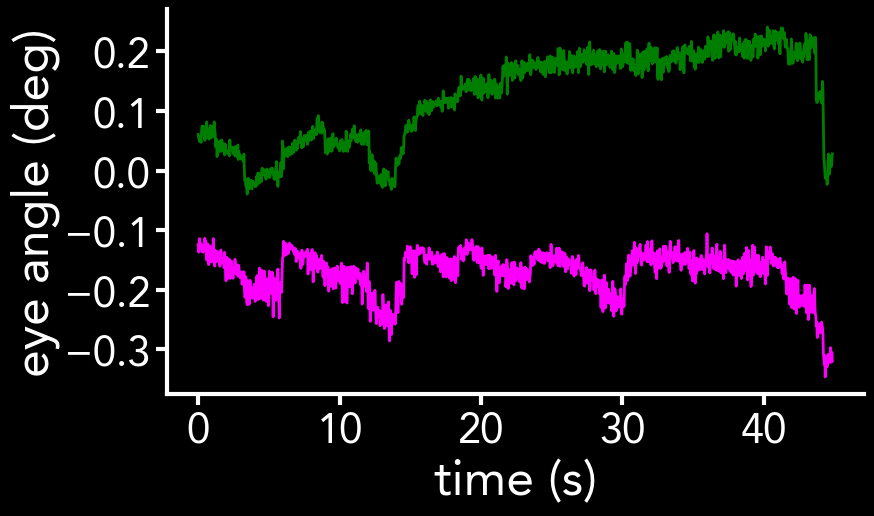

In [20]:
plotname = ''
fH, axH = plt.subplots(figsize= [9,5])

fps = 30

def trackPlot(track, fps, line_color='#ffffff'):
    phi = track['orientationRelative']
    t = np.multiply(track['t'], 1/fps)
    pH = plt.plot(t, phi, color=line_color, linewidth=2, alpha=.99)
    return pH

trackPlot(eyeL_track,fps,line_color='magenta')
trackPlot(eyeR_track,fps,line_color='green')

fontLabels = formatFigureMain(fH, axH, [])
axH.set_xlabel('time (s)', fontproperties=fontLabels)
axH.set_ylabel('eye angle (deg)', fontproperties=fontLabels)

# plt.ylim([-180,180])
# plt.xlim([60,75])
# plt.ylim([-15,0])

### Plot angular speed vs. time

Text(0, 0.5, 'eye velocity (deg/s)')

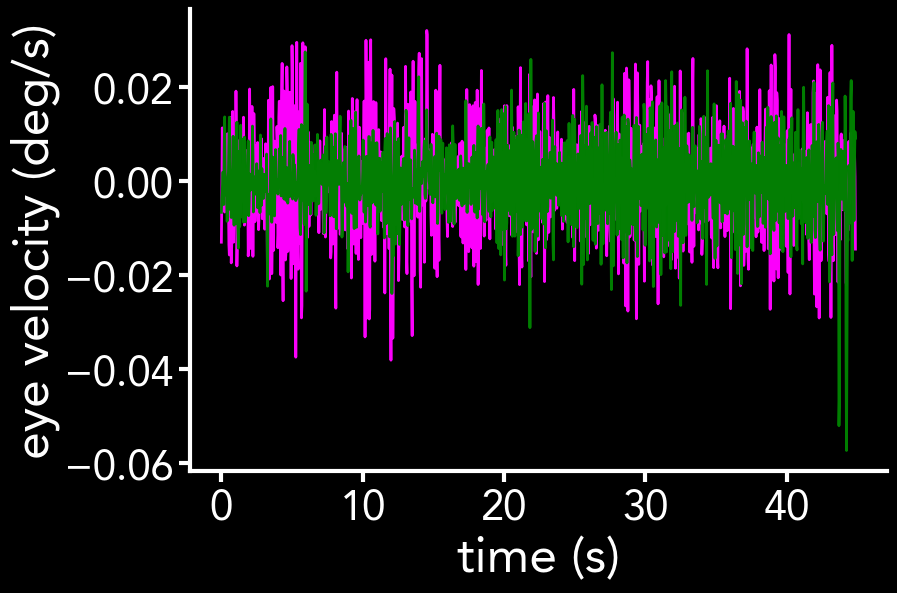

In [21]:
plotname = ''
fH, axH = plt.subplots(figsize= [9,6])

fps = 30

def trackPlot(track,fps,line_color = '#ffffff'):
    phi = np.gradient(track['orientationRelative'],1)
#     phi = np.gradient(track['orientation'],1)
    t = np.multiply(track['t'],1/fps)
    pH = plt.plot(t, phi, color=line_color, linewidth=2, alpha = .99);
    return pH

trackPlot(eyeL_track,fps,line_color='magenta')
trackPlot(eyeR_track,fps,line_color='green')

fontLabels = formatFigureMain(fH, axH, [])
axH.set_xlabel('time (s)', fontproperties=fontLabels)
axH.set_ylabel('eye velocity (deg/s)', fontproperties=fontLabels)

# plt.xlim([60,75])
# plt.xlim([90,105])
# plt.xlim([70,100])

### Plot angular acceleration vs. time

Text(0, 0.5, 'eye acceleration (deg/s/s)')

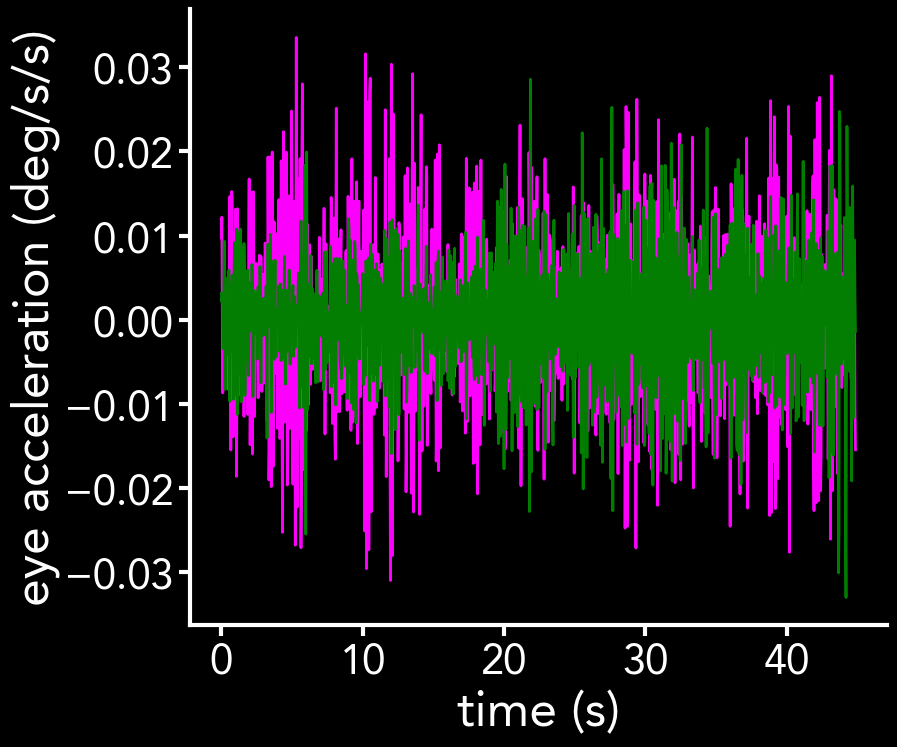

In [22]:
plotname = ''
fH, axH = plt.subplots(figsize= [9,8])

fps = 30

def trackPlot(track,fps,line_color = '#ffffff'):
    phi = np.gradient(np.gradient(track['orientationRelative'],1),1)
    t = np.multiply(track['t'],1/fps)
    pH = plt.plot(t, phi, color=line_color, linewidth=2, alpha = .99);
    return pH

trackPlot(eyeL_track,fps,line_color='magenta')
trackPlot(eyeR_track,fps,line_color='green')

fontLabels = formatFigureMain(fH, axH, [])
axH.set_xlabel('time (s)', fontproperties=fontLabels)
axH.set_ylabel('eye acceleration (deg/s/s)', fontproperties=fontLabels)

# plt.xlim([30,45])
# plt.xlim([90,105])
# plt.xlim([70,100])

### Plot orientation vs. time (Absolute)

Text(0, 0.5, 'eye angle (deg)')

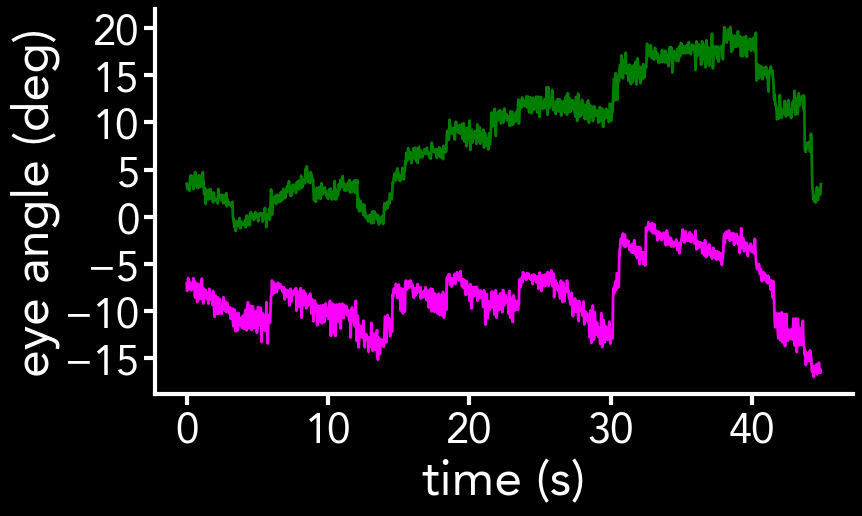

In [23]:
plotname = ''
fH, axH = plt.subplots(figsize= [9,5])

fps = 30

def trackPlot_Absolute(track,fps,line_color = '#ffffff'):
    phi = np.rad2deg(track['orientation'])
    t = np.multiply(track['t'],1/fps)
    pH = plt.plot(t, phi, color=line_color, linewidth=2, alpha = .99);
    return pH

trackPlot_Absolute(eyeL_track,fps,line_color='magenta')
trackPlot_Absolute(eyeR_track,fps,line_color='green')
trackPlot_Absolute(sb_track,fps,line_color='orange')

fontLabels = formatFigureMain(fH, axH, [])
axH.set_xlabel('time (s)', fontproperties=fontLabels)
axH.set_ylabel('eye angle (deg)', fontproperties=fontLabels)

# plt.xlim([0,120])
# plt.xlim([45,60])
# plt.ylim([-15,0])

### Plot orientation vs. time (Relative)

Text(0, 0.5, 'eye angle (degrees)')

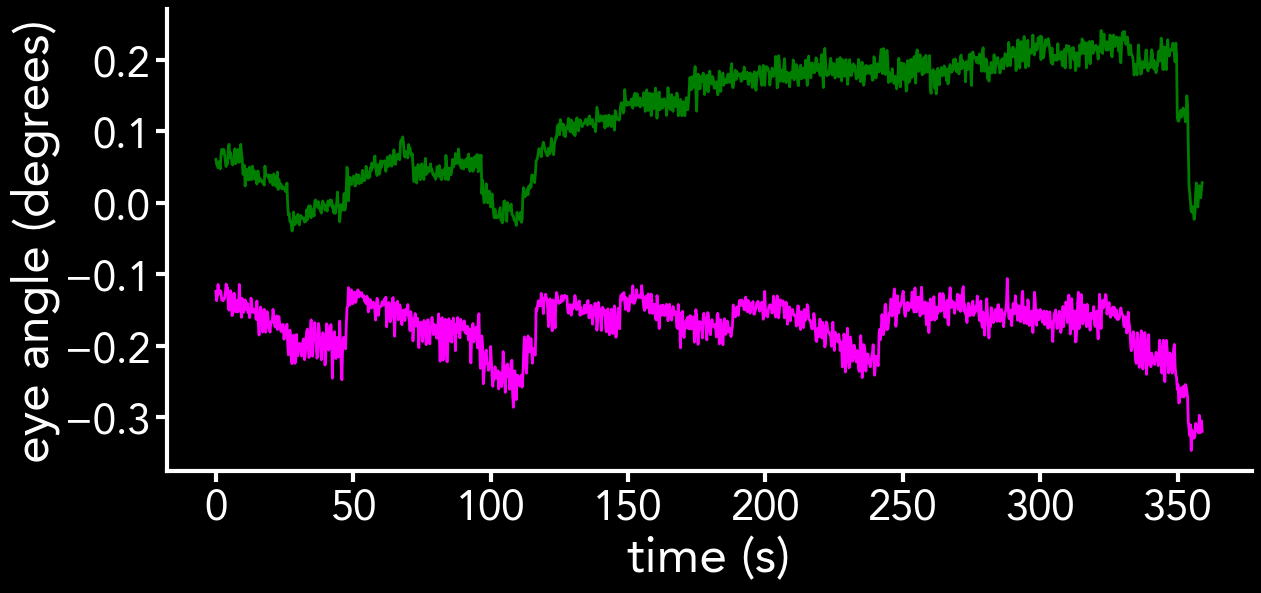

In [24]:
plotname = ''
fH, axH = plt.subplots(nrows=1,ncols=1,figsize= [14,6])

fps = 3.75

def trackPlot_Relative(track, refTrack, fps, line_color='#ffffff'):
    # Use orientationRelative instead of computing difference with refTrack
    phi = track['orientationRelative']  # Already in degrees
    t = np.multiply(track['t'], 1/fps)
    pH = axH.plot(t, phi, color=line_color, linewidth=2, alpha=.99)
    return pH

pH = trackPlot_Relative(eyeL_track, sb_track, fps, line_color='magenta')
pH = trackPlot_Relative(eyeR_track, sb_track, fps, line_color='green')

fontLabels = formatFigureMain(fH, axH, pH)
axH.set_xlabel('time (s)', fontproperties=fontLabels)
axH.set_ylabel('eye angle (degrees)', fontproperties=fontLabels)
# plt.xlim(350,550)